In [41]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam # optimizer
from tensorflow.keras.callbacks import Callback, EarlyStopping
from PIL import Image

# Fix every source of randomness so results can be reproduced
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [42]:
DATA_DIR = "split"            
SPLITS = {"train": "train", "val": "validation", "test": "test"}
IMG_EXT = (".pgm")

# ---- Settings ----
IMG_H, IMG_W = 60, 64              # height, width of every image
CLASSES = ["straight", "left", "right", "up"]
NUM_CLASSES = len(CLASSES)

def load_split(folder):
    #Load every image in a folder.

    X, y = [], []
    for root, _, files in os.walk(folder):
        for f in sorted(files):
            if not f.lower().endswith(IMG_EXT):
                continue                                      # skips .bad and other files
            img = np.asarray(Image.open(os.path.join(root, f)).convert("L"), dtype=np.float32)
            if img.shape != (IMG_H, IMG_W):                   # numpy shape is (height, width)
                raise ValueError(f"{f} has shape {img.shape}, expected {(IMG_H, IMG_W)}")
            X.append(img / 255.0)                             # scale pixels to [0, 1]
            y.append(CLASSES.index(os.path.splitext(f)[0].split("_")[1]))
    return np.stack(X)[..., None], np.array(y)               

X_train, y_train = load_split(os.path.join(DATA_DIR, SPLITS["train"]))
X_val,   y_val   = load_split(os.path.join(DATA_DIR, SPLITS["val"]))
X_test,  y_test  = load_split(os.path.join(DATA_DIR, SPLITS["test"]))

print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

Train: (436, 60, 64, 1)  Val: (93, 60, 64, 1)  Test: (95, 60, 64, 1)


In [43]:
# EpochTimer callback to record how long each epoch takes
class EpochTimer(Callback):
    # Records how long each epoch takes.
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.start)

In [44]:
# Load the pre-trained EfficinetNetB0 model
base_effnet = tf.keras.applications.EfficientNetB0(
    input_shape=(60, 64, 3), include_top=False, weights="imagenet")
base_effnet.trainable = False   #The pretrained weights will not change during training.

# Build the complete model
model_EffNetB0 = models.Sequential([
    layers.Input(shape=(60, 64, 3)),
    layers.Rescaling(255.0),          # 0–1 → 0–255; EfficientNet normalises internally
    base_effnet,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax"),
], name="EfficientNetB0")

model_EffNetB0.summary()

Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_11 (Rescaling)        │ (None, 60, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 2, 2, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [45]:
model_EffNetB0.compile(optimizer=Adam(1e-3),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
timer_head = EpochTimer()
history_EffNetB0_head = model_EffNetB0.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=32, callbacks=[timer_head], verbose=1)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 365ms/step - accuracy: 0.4266 - loss: 1.2564 - val_accuracy: 0.6882 - val_loss: 0.8556
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.7087 - loss: 0.7706 - val_accuracy: 0.7527 - val_loss: 0.5932
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.7775 - loss: 0.5988 - val_accuracy: 0.8387 - val_loss: 0.4574
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.8372 - loss: 0.4677 - val_accuracy: 0.8387 - val_loss: 0.3791
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.8922 - loss: 0.3471 - val_accuracy: 0.9355 - val_loss: 0.2996
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.8899 - loss: 0.3388 - val_accuracy: 0.9355 - val_loss: 0.2666
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.9220 - loss: 0.2746 - val_accuracy: 0.9892 - val_loss: 0.2013
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.9335 - loss: 0.2228 - val_accuracy: 0.9892 -

In [46]:
# Fine tuning the model

base_effnet.trainable = True
fine_tune_from = len(base_effnet.layers) - 30   # Fine-tune the last 30 layers of the model
for layer in base_effnet.layers[:fine_tune_from]:   # Freeze all layers except the last 30
    layer.trainable = False
for layer in base_effnet.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(int(tf.size(w)) for w in model_EffNetB0.trainable_weights)
print(f"Trainable params during fine-tuning: {n_trainable:,}")

model_EffNetB0.compile(optimizer=Adam(1e-5),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
timer_ft = EpochTimer()
history_EffNetB0_ft = model_EffNetB0.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=32, callbacks=[timer_ft], verbose=1)

Trainable params during fine-tuning: 1,647,844
Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 314ms/step - accuracy: 0.9839 - loss: 0.0715 - val_accuracy: 1.0000 - val_loss: 0.0410
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.9817 - loss: 0.0751 - val_accuracy: 1.0000 - val_loss: 0.0387
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.9954 - loss: 0.0384 - val_accuracy: 1.0000 - val_loss: 0.0333
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.9839 - loss: 0.0596 - val_accuracy: 1.0000 - val_loss: 0.0310
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.9885 - loss: 0.0539 - val_accuracy: 1.0000 - val_loss: 0.0306
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - accuracy: 0.9977 - loss: 0.0416 - val_accuracy: 1.0000 - val_loss: 0.0318
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - accuracy: 0.9817 - loss: 0.0514 - val_accuracy: 1.0000 - val_loss: 0.0288
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - ac

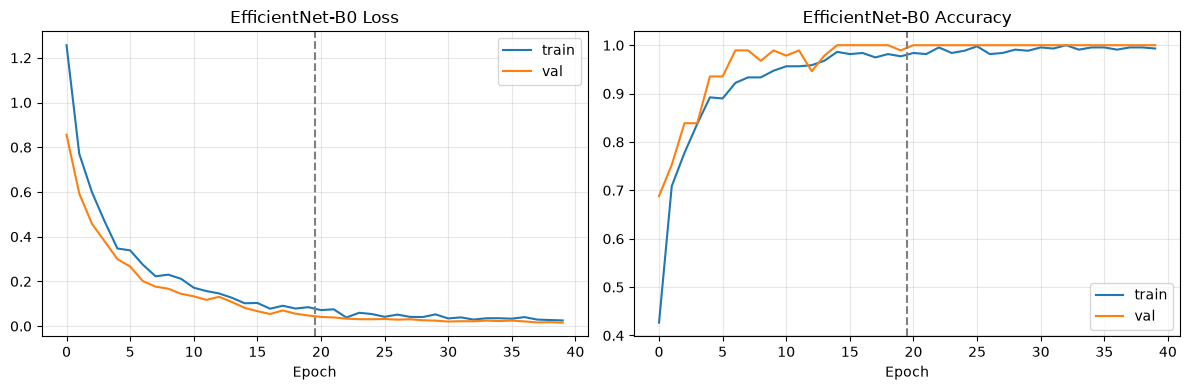

In [47]:

h = {k: history_EffNetB0_head.history[k] + history_EffNetB0_ft.history[k]
     for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(h["loss"], label="train"); ax1.plot(h["val_loss"], label="val")
ax2.plot(h["accuracy"], label="train"); ax2.plot(h["val_accuracy"], label="val")
for ax, t in [(ax1, "Loss"), (ax2, "Accuracy")]:
    ax.axvline(19.5, ls="--", c="gray")           # start of fine-tuning
    ax.set_title(f"EfficientNet-B0 {t}"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [48]:
test_loss_EffNetB0, test_accuracy_EffNetB0 = model_EffNetB0.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss_EffNetB0:.4f}")
print(f"Test Accuracy: {test_accuracy_EffNetB0:.4f}")
print(f"Test Accuracy: {test_accuracy_EffNetB0*100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 0.0278
Test Loss: 0.0278
Test Accuracy: 1.0000
Test Accuracy: 100.00%


2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/stepWARNING:tensorflow:5 out of the last 25 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000014D7F2E74C0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step 


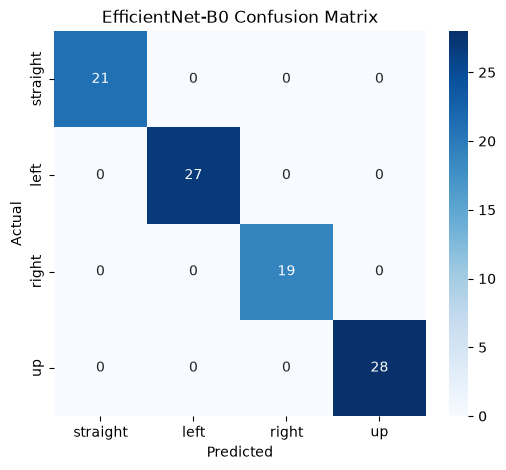

              precision    recall  f1-score   support

    straight     1.0000    1.0000    1.0000        21
        left     1.0000    1.0000    1.0000        27
       right     1.0000    1.0000    1.0000        19
          up     1.0000    1.0000    1.0000        28

    accuracy                         1.0000        95
   macro avg     1.0000    1.0000    1.0000        95
weighted avg     1.0000    1.0000    1.0000        95



In [49]:
y_pred_prob_EffNetB0 = model_EffNetB0.predict(X_test)
y_pred_EffNetB0 = np.argmax(y_pred_prob_EffNetB0, axis=1)

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_EffNetB0)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNet-B0 Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred_EffNetB0,
    target_names=CLASSES,
    digits=4
))

In [50]:
model_EffNetB0.save_weights("EfficientNetB0_CMU_Face.weights.h5")
print(f"Total params:        {model_EffNetB0.count_params():,}")
print(f"Size on disk:        {os.path.getsize('EfficientNetB0_CMU_Face.weights.h5')/1024:.1f} KB")
print(f"s/epoch (head):      {np.mean(timer_head.times[1:]):.3f}")
print(f"s/epoch (fine-tune): {np.mean(timer_ft.times[1:]):.3f}")

Total params:        4,214,055
Size on disk:        29957.5 KB
s/epoch (head):      1.109
s/epoch (fine-tune): 1.590
